In [9]:
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import pyplot as plt
import matplotlib.ticker as mticker
%matplotlib inline

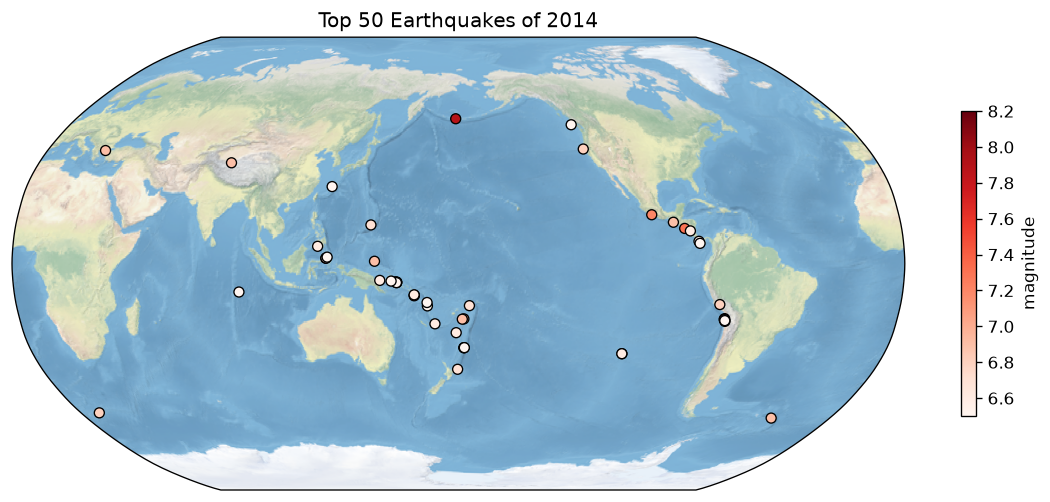

In [31]:
# 读取数据并筛选震级最大的前50次地震
df = pd.read_csv('usgs_earthquakes.csv')
top50 = df.sort_values('mag', ascending=False).head(50)

# 创建画布与以180°为中心的Robinson投影坐标系
plt.figure(figsize=(12, 6), dpi=120)
proj = ccrs.Robinson(180)
ax = plt.axes(projection=proj)

# 替换底图
ax.stock_img()

# 绘制前50次地震散点
plt.scatter(top50['longitude'], top50['latitude'],
            c=top50['mag'],
            cmap='Reds',
            edgecolors='black',
            linewidths=0.8,
            transform=ccrs.PlateCarree(),
            zorder=2)

# 添加色标与标题
plt.colorbar(label='magnitude', shrink=0.55)
plt.title('Top 50 Earthquakes of 2014')

plt.show()

In [32]:
# 读取数据
ds = xr.open_dataset('MERRA2_400.tavgM_2d_adg_Nx.202609.nc4', engine='netcdf4')
dust_aot = ds['DUEXTTFM'].isel(time=0)

In [33]:
# 全球最大值及其经纬度
i, j = np.where(dust_aot.values == np.max(dust_aot.values))
global_max_lat = float(dust_aot['lat'].values[i[0]])
global_max_lon = float(dust_aot['lon'].values[j[0]])
global_max_val = float(np.max(dust_aot.values))
print(global_max_lon, global_max_lat, global_max_val)

# 中国区域（73°E–136°E, 3°N–54°N）最大值及其经纬度
cn_sub = dust_aot.sel(lon=slice(73, 136), lat=slice(3, 54))
ci, cj = np.where(cn_sub.values == np.max(cn_sub.values))
cn_max_lat = float(cn_sub['lat'].values[ci[0]])
cn_max_lon = float(cn_sub['lon'].values[cj[0]])
cn_max_val = float(np.max(cn_sub.values))
print(cn_max_lon, cn_max_lat, cn_max_val)

15.0 17.0 0.18582791090011597
84.375 40.0 0.11846840381622314


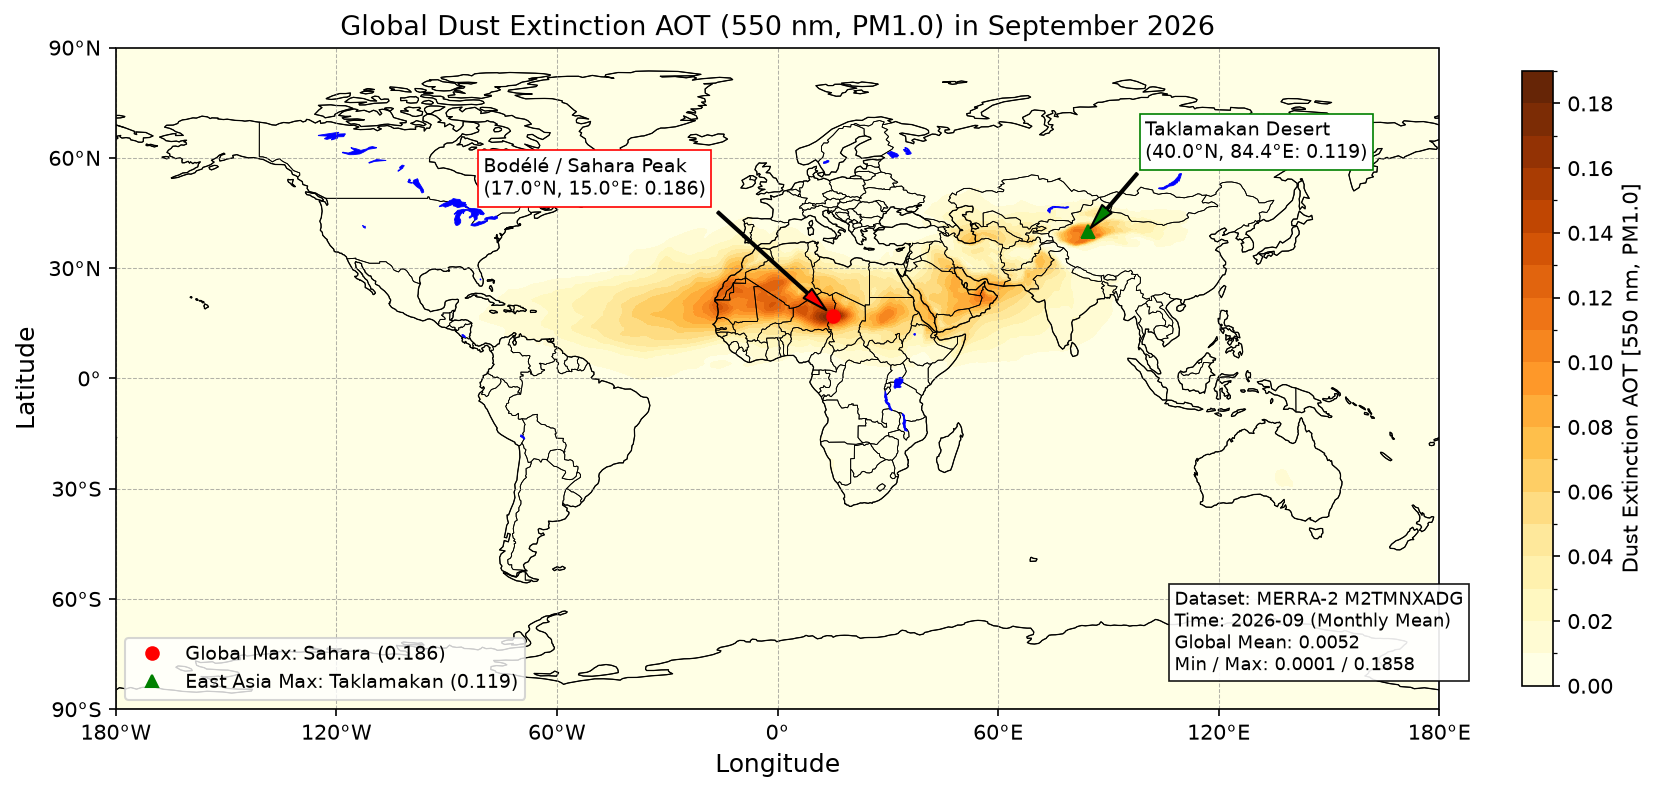

In [34]:
plt.figure(figsize=(12, 6), dpi=150)

# 投影
proj1 = ccrs.PlateCarree()
ax1 = plt.axes(projection=proj1)

# 填色图+色标
dust_aot.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 0.20, 0.01),
    cmap='YlOrBr',
    add_colorbar=True,
    cbar_kwargs={'shrink': 0.72, 'label': 'Dust Extinction AOT [550 nm, PM1.0]'}
)

# 地理要素
ax1.coastlines(resolution='110m', linewidth=0.6)
ax1.add_feature(
    cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_0_countries',
        scale='110m',
        facecolor='none',
        edgecolor='black',
        linewidth=0.4
    )
)
ax1.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='blue', linewidth=0.4)

# 网格线
gl1 = ax1.gridlines(crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.6, linestyle='--')
gl1.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl1.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

# X/Y轴刻度与标签
ax1.set(xlim=(-180, 180), ylim=(-90, 90))
ax1.set_xticks(np.arange(-180, 181, 60))
ax1.set_xticklabels(['180°W', '120°W', '60°W', '0°', '60°E', '120°E', '180°E'])
ax1.set_yticks(np.arange(-90, 91, 30))
ax1.set_yticklabels(['90°S', '60°S', '30°S', '0°', '30°N', '60°N', '90°N'])
ax1.set_xlabel('Longitude', fontsize=12)
ax1.set_ylabel('Latitude', fontsize=12)

# 标题
ax1.set_title('Global Dust Extinction AOT (550 nm, PM1.0) in September 2026', fontsize=13)

# 图例
ax1.plot(15.0, 17.0, 'ro', markersize=6, label='Global Max: Sahara (0.186)', transform=ccrs.PlateCarree())
ax1.plot(84.375, 40.0, 'g^', markersize=6, label='East Asia Max: Taklamakan (0.119)', transform=ccrs.PlateCarree())
ax1.legend(loc='lower left', frameon=True, framealpha=0.8, fontsize=9)

# 箭头标注
ax1.annotate(
    'Bodélé / Sahara Peak\n(17.0°N, 15.0°E: 0.186)',
    xy=(15.0, 17.0),
    xytext=(-80, 50),
    fontsize=9,
    bbox=dict(boxstyle='square', fc='white', ec='red', linewidth=0.8),
    arrowprops=dict(facecolor='red', shrink=0.05, width=1.0, headwidth=6)
)
ax1.annotate(
    'Taklamakan Desert\n(40.0°N, 84.4°E: 0.119)',
    xy=(84.375, 40.0),
    xytext=(100, 60),
    fontsize=9,
    bbox=dict(boxstyle='square', fc='white', ec='green', linewidth=0.8),
    arrowprops=dict(facecolor='green', shrink=0.05, width=1.0, headwidth=6)
)

# 文本框
global_mean = float(dust_aot.mean())
global_max = float(dust_aot.max())
global_min = float(dust_aot.min())
info_global = (
    f'Dataset: MERRA-2 M2TMNXADG\n'
    f'Time: 2026-09 (Monthly Mean)\n'
    f'Global Mean: {global_mean:.4f}\n'
    f'Min / Max: {global_min:.4f} / {global_max:.4f}'
)
ax1.text(
    0.8, 0.05, info_global,
    transform=ax1.transAxes,
    ha='left', va='bottom', fontsize=8.5,
    bbox=dict(boxstyle='square', fc='white', ec='black', alpha=0.9, linewidth=0.8)
)

plt.tight_layout()
plt.show()

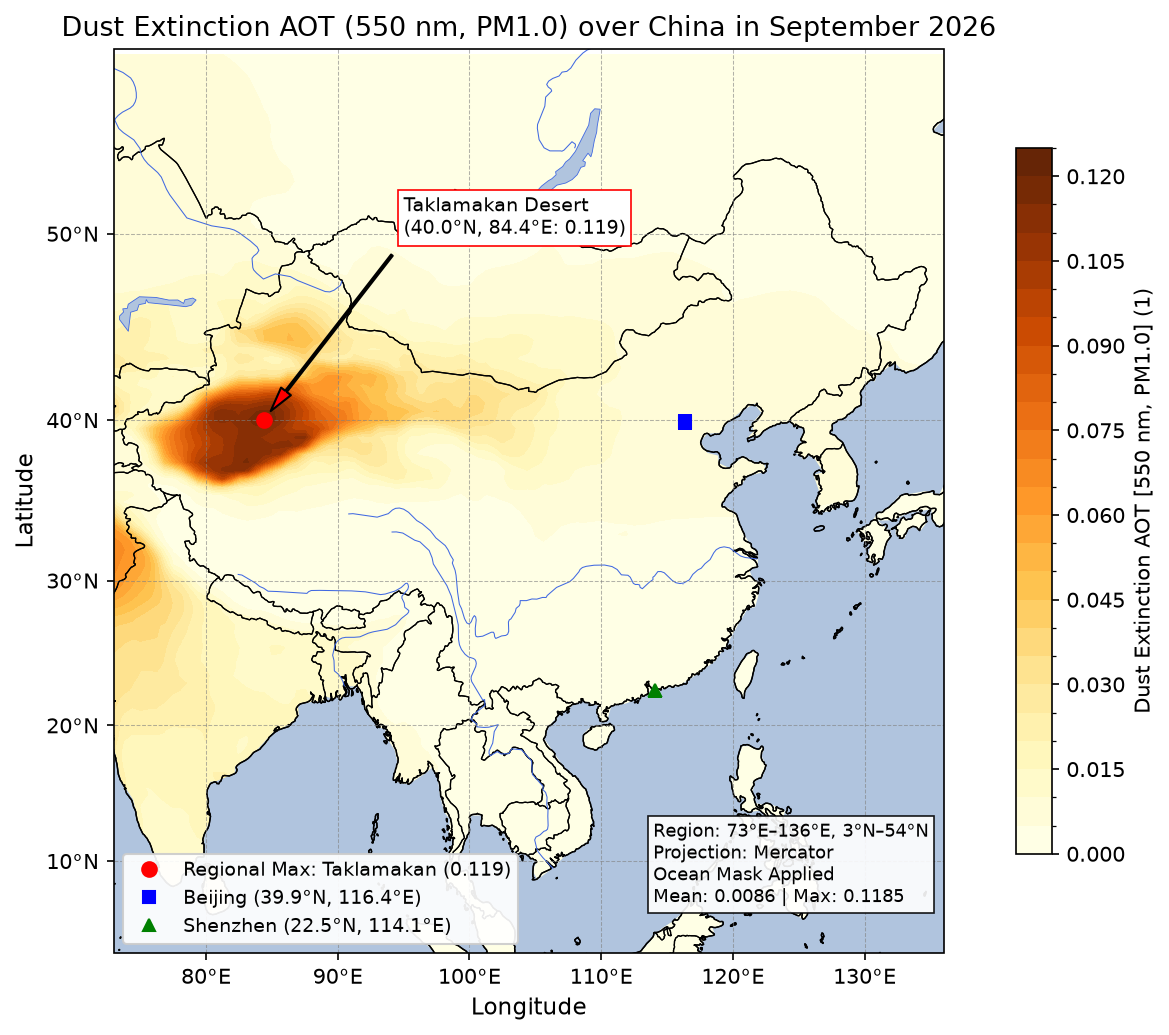

In [37]:
plt.figure(figsize=(10, 7), dpi=150)

# 不同的投影
proj2 = ccrs.Mercator()
ax2 = plt.axes(projection=proj2)

# 填色图+色标
china_aot = dust_aot.sel(lon=slice(70, 140), lat=slice(0, 58))
china_aot.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 0.13, 0.005),
    cmap='YlOrBr',
    add_colorbar=True,
    cbar_kwargs={'shrink': 0.78, 'label': 'Dust Extinction AOT [550 nm, PM1.0] (1)'}
)

# 设置中国区域范围
extent = [73, 136, 3, 54]
ax2.set_extent(extent)

# 海洋掩膜+地理要素
ax2.add_feature(cfeature.OCEAN, facecolor='lightsteelblue', zorder=1)
ax2.coastlines(resolution='50m', linewidth=0.7, zorder=2)
ax2.add_feature(
    cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_0_countries',
        scale='50m',
        facecolor='none',
        edgecolor='black',
        linewidth=0.6
    ),
    zorder=2
)
ax2.add_feature(cfeature.RIVERS, edgecolor='royalblue', linewidth=0.5, zorder=2)
ax2.add_feature(cfeature.LAKES, edgecolor='royalblue', facecolor='lightsteelblue', linewidth=0.4, zorder=2)

# 网格线
gl2 = ax2.gridlines(crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.6, linestyle='--', zorder=3)
gl2.xlocator = mticker.FixedLocator(np.arange(80, 136, 10))
gl2.ylocator = mticker.FixedLocator(np.arange(10, 55, 10))

# X/Y轴刻度与标签
ax2.set_xticks(np.arange(80, 136, 10), crs=ccrs.PlateCarree())
ax2.set_xticklabels(['80°E', '90°E', '100°E', '110°E', '120°E', '130°E'])
ax2.set_yticks(np.arange(10, 55, 10), crs=ccrs.PlateCarree())
ax2.set_yticklabels(['10°N', '20°N', '30°N', '40°N', '50°N'])
ax2.set_xlabel('Longitude', fontsize=11)
ax2.set_ylabel('Latitude', fontsize=11)

# 标题
ax2.set_title('Dust Extinction AOT (550 nm, PM1.0) over China in September 2026', fontsize=13)

# 图例
ax2.plot(84.375, 40.0, 'ro', markersize=7, label='Regional Max: Taklamakan (0.119)', transform=ccrs.PlateCarree(), zorder=4)
ax2.plot(116.40, 39.90, 'bs', markersize=6, label='Beijing (39.9°N, 116.4°E)', transform=ccrs.PlateCarree(), zorder=4)
ax2.plot(114.06, 22.54, 'g^', markersize=6, label='Shenzhen (22.5°N, 114.1°E)', transform=ccrs.PlateCarree(), zorder=4)
ax2.legend(loc='lower left', frameon=True, framealpha=0.92, fontsize=9)

# 箭头标注
ax2.annotate(
    'Taklamakan Desert\n(40.0°N, 84.4°E: 0.119)',
    xy=(84.375, 40.0),
    xytext=(95, 50),
    transform=ccrs.PlateCarree(),
    fontsize=9,
    bbox=dict(boxstyle='square', fc='white', ec='red', linewidth=0.8),
    arrowprops=dict(facecolor='red', shrink=0.05, width=1.0, headwidth=6),
    zorder=5
)

# 文本框
cn_sub = dust_aot.sel(lon=slice(73, 136), lat=slice(3, 54))
info_cn = (
    f'Region: 73°E–136°E, 3°N–54°N\n'
    f'Projection: Mercator\n'
    f'Ocean Mask Applied\n'
    f'Mean: {float(cn_sub.mean()):.4f} | Max: {float(cn_sub.max()):.4f}'
)
ax2.text(
    0.65, 0.05, info_cn,
    transform=ax2.transAxes,
    ha='left', va='bottom', fontsize=8.5,
    bbox=dict(boxstyle='square', fc='white', ec='black', alpha=0.9, linewidth=0.8),
    zorder=5
)

plt.tight_layout()
plt.show()